In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler  # for scaling time features

In [10]:
# Base directory for AntM2C 10M dataset
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"

# Main preprocessed folder
preprocessed_dir = f"{base_dir}/AntM2C_preprocessed"

# Time-related CSV from split_features
time_features_csv = f"{preprocessed_dir}/split_features/df_time.csv"

# Combined preprocessed dataframe
df_processed_pkl = f"{preprocessed_dir}/df_processed.pkl"

# Interactions CSV (if needed later)
# interactions_csv = f"{preprocessed_dir}/interactions_clean.csv"   # if exists in your workflow

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [12]:
df_time = pd.read_csv(time_features_csv)

print("Loaded df_time.csv with shape:", df_time.shape)
df_time.head()

Loaded df_time.csv with shape: (3730329, 6)


,log_time,hour,dayofweek,is_weekend,hour_sin,hour_cos
0,2023-07-14 00:21:44,0,4,False,0.000000e+00,1.000000
1,2023-07-18 12:45:30,12,1,False,1.224647e-16,-1.000000
2,2023-08-01 09:28:15,9,1,False,7.071068e-01,-0.707107
3,2023-08-03 23:19:06,23,3,False,-2.588190e-01,0.965926
4,2023-08-01 20:24:21,20,1,False,-8.660254e-01,0.500000


The df_time.csv file contains the pre-engineered temporal features for each interaction.
These include:
*   log_time: Original timestamp in datetime format
*   hour: Hour of day (0–23)
*   dayofweek: Day of week (0–6)
*   is_weekend: Boolean indicating weekend/weekday
*   hour_sin, hour_cos: Cyclic encodings of hour-of-day

This preprocessing was already performed during dataset preparation, so this notebook focuses on validating the data and preparing it for Time2Vec integration.

#### Convert log_time to datetime

In [13]:
df_time["datetime"] = pd.to_datetime(df_time["log_time"], errors='coerce')
print(df_time["datetime"].describe())

count                          3730329
mean     2023-07-25 21:51:35.364042496
min                2023-07-10 00:00:02
25%                2023-07-18 08:19:42
50%                2023-07-25 22:23:26
75%                2023-08-02 16:09:55
max                2023-08-09 23:59:59
Name: datetime, dtype: object


#### Check for missing timestamps

In [14]:
missing_ts = df_time["datetime"].isna().sum()
print("Missing timestamps:", missing_ts)

Missing timestamps: 0


#### Plot hourly distribution

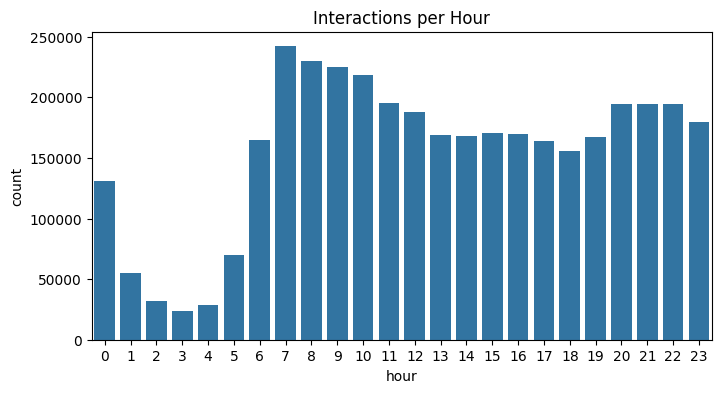

In [15]:
plt.figure(figsize=(8,4))
sns.countplot(x=df_time["hour"])
plt.title("Interactions per Hour")
plt.show()

#### Plot weekday distribution

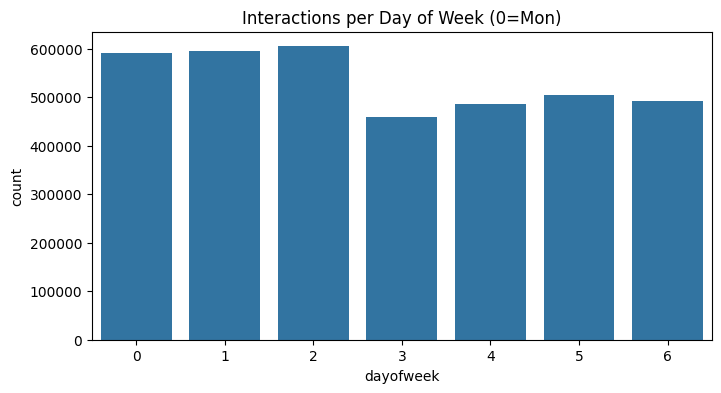

In [16]:
plt.figure(figsize=(8,4))
sns.countplot(x=df_time["dayofweek"])
plt.title("Interactions per Day of Week (0=Mon)")
plt.show()

#### Check cyclic encoding range

In [17]:
print("hour_sin range:", df_time["hour_sin"].min(), df_time["hour_sin"].max())
print("hour_cos range:", df_time["hour_cos"].min(), df_time["hour_cos"].max())

hour_sin range: -1.0 1.0
hour_cos range: -1.0 1.0


### Engineer Base Time Features

The AntM2C preprocessed time file already includes several engineered temporal features such as:


*   Hour of day
*   Day of week
*   Weekend indicator
*   Cyclic encodings (hour_sin, hour_cos)

However, the Time2Vec module requires at least one continuous time signal, typically:
*   A normalized Unix timestamp, or
*   A continuous “time since start/end” measure

Therefore, this step adds a continuous normalized timestamp (unix_time_norm) that captures global temporal drift across the dataset.

We then:
1.   Convert log_time into a Unix timestamp
2.   Normalize it using StandardScaler
3.   Convert boolean flags to numeric (e.g., is_weekend -> 0/1)
4.   Build the final set of features to feed into Time2Vec

These encoded time features will be used as inputs to the Time2Vec layer in the full ColdFusionX architecture.

In [18]:
# Convert log_time -> Unix time (continuous)

# (Just to make sure date time is created)
df_time["datetime"] = pd.to_datetime(df_time["log_time"], errors='coerce')

# Convert to Unix timestamp in seconds (int)
df_time["unix_time"] = df_time["datetime"].astype('int64') // 1_000_000_000

print(df_time[["log_time", "datetime", "unix_time"]].head())

              log_time            datetime   unix_time
0  2023-07-14 00:21:44 2023-07-14 00:21:44  1689294104
1  2023-07-18 12:45:30 2023-07-18 12:45:30  1689684330
2  2023-08-01 09:28:15 2023-08-01 09:28:15  1690882095
3  2023-08-03 23:19:06 2023-08-03 23:19:06  1691104746
4  2023-08-01 20:24:21 2023-08-01 20:24:21  1690921461


In [19]:
# Normalize Unix Time (Essential for Time2Vec)
scaler = StandardScaler()

df_time["unix_time_norm"] = scaler.fit_transform(
    df_time[["unix_time"]]
)

print(df_time["unix_time_norm"].describe())

count    3.730329e+06
mean     6.471484e-14
std      1.000000e+00
min     -1.784405e+00
25%     -8.482854e-01
50%      2.480079e-03
75%      8.705938e-01
max      1.692257e+00
Name: unix_time_norm, dtype: float64


 Saving scaler stats for reproducibility

In [20]:
scaler_stats = {
    "mean": float(scaler.mean_),
    "scale": float(scaler.scale_)
}

with open(f"{preprocessed_dir}/split_features/scaler_stats_time.json", "w") as f:
    json.dump(scaler_stats, f)

scaler_stats

{'mean': 1690321895.3640416, 'scale': 770393.2955774534}

### Convert boolean features (e.g., is_weekend) to numeric

In [21]:
if df_time["is_weekend"].dtype == "object":
    df_time["is_weekend"] = df_time["is_weekend"].map({"true": 1, "false": 0})

df_time["is_weekend"] = df_time["is_weekend"].astype(int)

Selecting the final Time Features for Time2Vec

In [22]:
time_feature_cols = [
    "unix_time_norm",
    "hour_sin",
    "hour_cos",
    "dayofweek",
    "is_weekend"
]

df_time_features = df_time[time_feature_cols]

print("Selected time feature columns:", time_feature_cols)
df_time_features.head()

Selected time feature columns: ['unix_time_norm', 'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend']


,unix_time_norm,hour_sin,hour_cos,dayofweek,is_weekend
0,-1.334113,0.000000e+00,1.000000,4,0
1,-0.827584,1.224647e-16,-1.000000,1,0
2,0.727161,7.071068e-01,-0.707107,1,0
3,1.016170,-2.588190e-01,0.965926,3,0
4,0.778259,-8.660254e-01,0.500000,1,0


Convert to PyTorch Tensor

In [23]:
time_features_tensor = torch.tensor(
    df_time_features.values, dtype=torch.float32
)

print("Tensor shape:", time_features_tensor.shape)

Tensor shape: torch.Size([3730329, 5])


Save the Time Featueres

In [24]:
torch.save(
    time_features_tensor,
    f"{preprocessed_dir}/time_features_raw.pt"
)

with open(f"{preprocessed_dir}/time_feature_columns.json", "w") as f:
    json.dump(time_feature_cols, f)

print("Saved time features and column metadata.")

Saved time features and column metadata.


##Define the Time2Vec Encoder (PyTorch Module)

Time2Vec is a learnable time representation proposed by Kazemi & Goel (2019).
Unlike fixed sinusoidal encodings, Time2Vec learns both:
*   A linear component to capture global temporal trends
*   Several periodic components (sine terms) to model recurring patterns

For a time input vector t (e.g. [unix_time_norm, hour_sin, hour_cos, dayofweek, is_weekend]), Time2Vec learns:
*   One linear projection: L(t) = w₀ᵀ t + b₀
*   Several periodic projections: Pᵢ(t) = sin(wᵢᵀ t + bᵢ) for i = 1…k

The final Time2Vec embedding is the concatenation:

Time2Vec(t) = 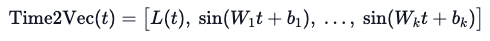

In this notebook, we implement a general Time2Vec PyTorch layer:
*   Input shape: (batch_size, in_features) -> here: (N, 5)
*   Output shape: (batch_size, out_features) where out_features = 1 + k
*   The layer is fully differentiable and will be trained jointly with the CTR model.

This notebook will:
1.   Define the Time2Vec module
2.   Instantiate it with the current time feature dimension (5)
3.   Test it on a random batch to verify shape and value ranges

In [34]:
class Time2Vec(nn.Module):
    """
    Time2Vec layer as described by Kazemi & Goel (2019).

    Given an input of shape (batch_size, in_features),
    outputs a time embedding of shape (batch_size, out_features),
    where out_features = linear_dim + periodic_dim.

    We use:
      - 1 linear component
      - (k) periodic components with sine activations
    """
    def __init__(self, in_features: int, k: int):
        """
        Args:
            in_features: number of input time features (e.g. 5)
            k: number of periodic components (embedding_dim = 1 + k)
        """
        super(Time2Vec, self).__init__()

        # Linear part: scalar per time vector
        self.linear = nn.Linear(in_features, 1)

        # Periodic part: k sine components
        self.periodic = nn.Linear(in_features, k)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: tensor of shape (batch_size, in_features)
        Returns:
            Tensor of shape (batch_size, 1 + k)
        """
        # Linear component
        v_linear = self.linear(x)                 # (B, 1)

        # Periodic component
        v_periodic = torch.sin(self.periodic(x))  # (B, k)

        # Concatenate along last dimension
        return torch.cat([v_linear, v_periodic], dim=-1)

We already know,

In [35]:
time_features_tensor.shape  # torch.Size([3730329, 5])

torch.Size([3730329, 5])

Therefore,
*   in_features = 5
*   Choose e.g. k = 7 → total time embedding dim = 8

In [36]:
in_features = time_features_tensor.shape[1]  # 5
k = 7                                        # periodic components
time2vec_dim = 1 + k                         # total output dimensions

time2vec_layer = Time2Vec(in_features=in_features, k=k).to(device)
print(time2vec_layer)

Time2Vec(
  (linear): Linear(in_features=5, out_features=1, bias=True)
  (periodic): Linear(in_features=5, out_features=7, bias=True)
)


Testing on a Small Batch

In [37]:
# Take a small random subset for testing
batch_idx = torch.randint(0, time_features_tensor.shape[0], (1024,))
time_batch = time_features_tensor[batch_idx].to(device)  # (1024, 5)

with torch.no_grad():
    t2v_out = time2vec_layer(time_batch)

print("Input shape:", time_batch.shape)         # (1024, 5)
print("Output shape:", t2v_out.shape)           # (1024, 8)
print("First row (Time2Vec embedding):")
print(t2v_out[0])

Input shape: torch.Size([1024, 5])
Output shape: torch.Size([1024, 8])
First row (Time2Vec embedding):
tensor([-0.2118, -0.2394,  0.7116, -0.2542,  0.4126, -0.3638,  0.4481,  0.5988])


### Building Time Feature Tensors for the CTR Pipeline

The purpose of this is to produce a clean, final tensor of time-based features that can be directly fed into the CTR model.

The ColdFusionX architecture handles time in two components:

1.   Raw Time Features
*   These include normalized Unix time, cyclic encodings, weekday indicators, etc.
*   They form the input to the Time2Vec layer inside the model.

2.   Time2Vec Representation (during model training)


*   The model uses a learned Time2Vec layer to generate richer temporal embeddings.
*   These are fused with image, text, and ID embeddings in the multimodal pipeline.

In this notebook however, we prepare and save the raw time feature tensor so that it can be loaded efficiently during training and evaluation.

Validate Final Tensor

In [40]:
print("Final time features tensor shape:", time_features_tensor.shape)
print("Number of time features:", len(time_feature_cols))
print("Time feature columns:", time_feature_cols)

Final time features tensor shape: torch.Size([3730329, 5])
Number of time features: 5
Time feature columns: ['unix_time_norm', 'hour_sin', 'hour_cos', 'dayofweek', 'is_weekend']


Check for NaNs or Infs

In [41]:
print("NaNs:", torch.isnan(time_features_tensor).sum().item())
print("Infs:", torch.isinf(time_features_tensor).sum().item())

NaNs: 0
Infs: 0


#### Compute Norm Distribution
(To ensure there are no extreme outliers in the time vectors)

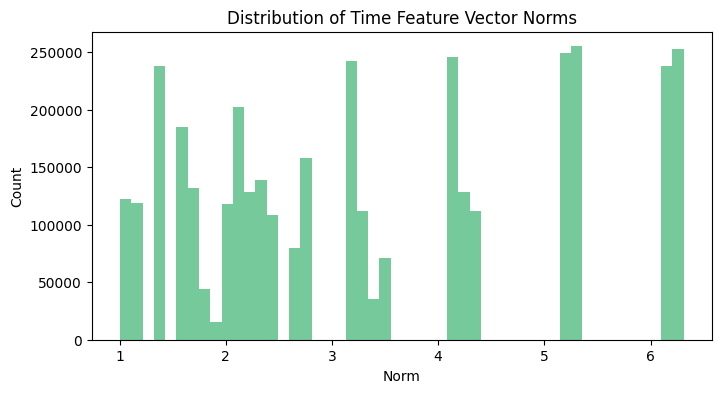

Mean norm: 3.401494026184082
Std norm: 1.677732229232788


In [42]:
time_norms = torch.norm(time_features_tensor, dim=1)

plt.figure(figsize=(8,4))
plt.hist(time_norms.numpy(), bins=50, alpha=0.7, color='mediumseagreen')
plt.title("Distribution of Time Feature Vector Norms")
plt.xlabel("Norm")
plt.ylabel("Count")
plt.show()

print("Mean norm:", time_norms.mean().item())
print("Std norm:", time_norms.std().item())

In [43]:
final_time_tensor_path = f"{preprocessed_dir}/time_features_final.pt"
torch.save(time_features_tensor, final_time_tensor_path)

print("Saved:", final_time_tensor_path)

Saved: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/time_features_final.pt


In [44]:
# Save column names
final_time_cols_path = f"{preprocessed_dir}/time_features_columns.json"
with open(final_time_cols_path, "w") as f:
    json.dump(time_feature_cols, f)

print("Saved column metadata:", final_time_cols_path)

Saved column metadata: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/time_features_columns.json


In [45]:
loaded_time_tensor = torch.load(final_time_tensor_path)

print("Loaded tensor shape:", loaded_time_tensor.shape)
print("Matches original:", loaded_time_tensor.shape == time_features_tensor.shape)

Loaded tensor shape: torch.Size([3730329, 5])
Matches original: True


### Pre-Test Time2Vec + Visual Diagnostics


1.   Forward pass on a random sample of time features
2.   Distribution analysis of resulting Time2Vec embeddings
3.   Visualization of embedding norms
4.   Inspection of individual embedding vectors

These checks ensure that the Time2Vec representation is numerically stable and capable of modeling both global and cyclic temporal patterns, which are essential for handling temporal drift in CTR prediction.

Generate Time2Vec embeddings for a sample

In [46]:
sample_size = 20000
idx = torch.randint(0, time_features_tensor.shape[0], (sample_size,))
time_sample = time_features_tensor[idx].to(device)

with torch.no_grad():
    t2v_sample = time2vec_layer(time_sample).cpu()

print("Sample Time2Vec shape:", t2v_sample.shape)

Sample Time2Vec shape: torch.Size([20000, 8])


In [47]:
# inspecting a few embedddings
for i in range(3):
    print(f"Sample {i}:", t2v_sample[i])

Sample 0: tensor([ 1.5200, -0.3857,  0.9749,  0.9608,  0.7945, -0.9529,  0.9401,  0.9912])
Sample 1: tensor([-0.1575, -0.2060,  0.1525,  0.2609,  0.6313, -0.8197, -0.8468, -0.2080])
Sample 2: tensor([-0.0369, -0.0035, -0.1410,  0.2940,  0.6702, -0.5060, -0.8594,  0.1075])


Norm distribution of Time2Vec embeddings

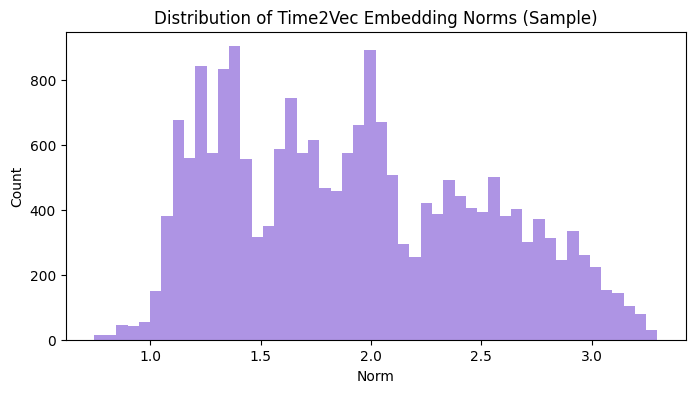

Mean norm: 1.9279807
Std norm: 0.5787113


In [48]:
t2v_norms = torch.norm(t2v_sample, dim=1).numpy()

plt.figure(figsize=(8,4))
plt.hist(t2v_norms, bins=50, color="mediumpurple", alpha=0.75)
plt.title("Distribution of Time2Vec Embedding Norms (Sample)")
plt.xlabel("Norm")
plt.ylabel("Count")
plt.show()

print("Mean norm:", np.mean(t2v_norms))
print("Std norm:", np.std(t2v_norms))

Visualize how Time2Vec varies with hour-of-day

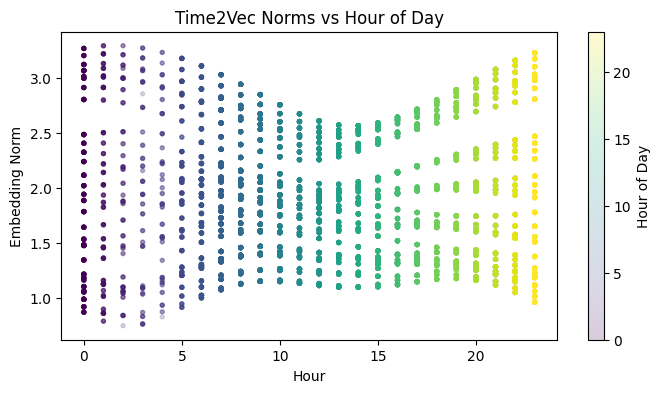

In [49]:
hours = df_time.iloc[idx.numpy()]["hour"].values
plt.figure(figsize=(8,4))
plt.scatter(hours, t2v_norms, alpha=0.2, s=8, c=hours, cmap="viridis")
plt.colorbar(label="Hour of Day")
plt.title("Time2Vec Norms vs Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Embedding Norm")
plt.show()

 Inspect linear vs periodic components separately

In [51]:
linear_part = t2v_sample[:, 0].numpy()
periodic_part = t2v_sample[:, 1:].numpy()

print("Linear part stats:", np.mean(linear_part), np.std(linear_part))
print("Periodic part stats:", np.mean(periodic_part), np.std(periodic_part))

Linear part stats: 0.69067025 0.8642867
Periodic part stats: 0.20094162 0.60301113


### References
Kazemi, S.M. et al. (2019). Time2Vec: Learning a Vector Representation of Time. Available from https://doi.org/10.48550/ARXIV.1907.05321 [Accessed 21 September 2025].